In [1]:
import os
import numpy as np
import pandas as pd
from skimage import io
from skimage.measure import regionprops, label
from skimage.transform import resize
from PIL import Image

import torch
import torch.nn as nn
from torchvision import transforms
from torch.utils.data import Dataset, DataLoader

# === CONFIG ===
mask_path = r"C:\Users\Liyua\Downloads\FCday3\segmentedFCday32.tif"
raw_image_path  = r"C:\Users\Liyua\Documents\20250307-FC treat AT2 domes\FC group\day3\FCday3_2.tif" 
crop_dir = "crops_FC"
latent_dim = 128
output_csv = "morphology_latent_vectors_FC_day3.csv"

# === STEP 1: CROP CELLS ===
os.makedirs(crop_dir, exist_ok=True)
mask = io.imread(mask_path)
raw = io.imread(raw_image_path)
assert mask.shape == raw.shape, "Raw image and mask must have the same shape."

labeled = label(mask)
cell_id = 0
for region in regionprops(labeled):
    minr, minc, maxr, maxc = region.bbox
    crop = raw[minr:maxr, minc:maxc]
    if crop.shape[0] >= 10 and crop.shape[1] >= 10:
        crop_resized = resize(crop, (64, 64), preserve_range=True).astype(np.uint8)
        Image.fromarray(crop_resized).save(os.path.join(crop_dir, f"cell_{cell_id}.png"))
        cell_id += 1
print(f"Saved {cell_id} cropped cells.")

# === STEP 2: DEFINE DATASET ===
transform = transforms.Compose([
    transforms.Grayscale(),
    transforms.ToTensor()
])

class CellCropDataset(Dataset):
    def __init__(self, crop_dir):
        self.files = sorted(os.listdir(crop_dir))
        self.paths = [os.path.join(crop_dir, f) for f in self.files]
    def __len__(self): return len(self.paths)
    def __getitem__(self, idx):
        img = Image.open(self.paths[idx])
        return transform(img), self.files[idx].replace('.png', '')

dataset = CellCropDataset(crop_dir)
loader = DataLoader(dataset, batch_size=16, shuffle=True)

# === STEP 3: AUTOENCODER ===
class MorphAutoencoder(nn.Module):
    def __init__(self, latent_dim=128):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Conv2d(1, 16, 3, 2, 1), nn.ReLU(),   # 32×32
            nn.Conv2d(16, 32, 3, 2, 1), nn.ReLU(),  # 16×16
            nn.Flatten(),
            nn.Linear(32 * 16 * 16, latent_dim)
        )
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 32 * 16 * 16),
            nn.Unflatten(1, (32, 16, 16)),
            nn.ConvTranspose2d(32, 16, 3, 2, 1, output_padding=1), nn.ReLU(),
            nn.ConvTranspose2d(16, 1, 3, 2, 1, output_padding=1), nn.Sigmoid()
        )
    def forward(self, x):
        z = self.encoder(x)
        recon = self.decoder(z)
        return recon, z

model = MorphAutoencoder(latent_dim=latent_dim)
opt = torch.optim.Adam(model.parameters(), lr=1e-3)
loss_fn = nn.MSELoss()

# === STEP 4: TRAIN AUTOENCODER ===
print("🚀 Training autoencoder...")
for epoch in range(10):
    model.train()
    total_loss = 0
    for batch, _ in loader:
        recon, z = model(batch)
        loss = loss_fn(recon, batch)
        opt.zero_grad()
        loss.backward()
        opt.step()
        total_loss += loss.item()
    print(f"Epoch {epoch+1}: Loss = {total_loss / len(loader):.4f}")

# === STEP 5: ENCODE CELLS ===
print("🔍 Encoding morphology vectors...")
model.eval()
all_latents = []
all_ids = []
with torch.no_grad():
    for batch, ids in DataLoader(dataset, batch_size=16):
        _, z = model(batch)
        all_latents.append(z.numpy())
        all_ids.extend(ids)

df = pd.DataFrame(np.vstack(all_latents), index=all_ids)
df.to_csv(output_csv)
print(f"Latent vectors saved to: {output_csv}")


FileNotFoundError: [Errno 2] No such file or directory: 'C:\\Users\\Liyua\\Downloads\\FCday3\\segmentedFCday32.tif'

C:\Users\Liyua\anaconda3\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


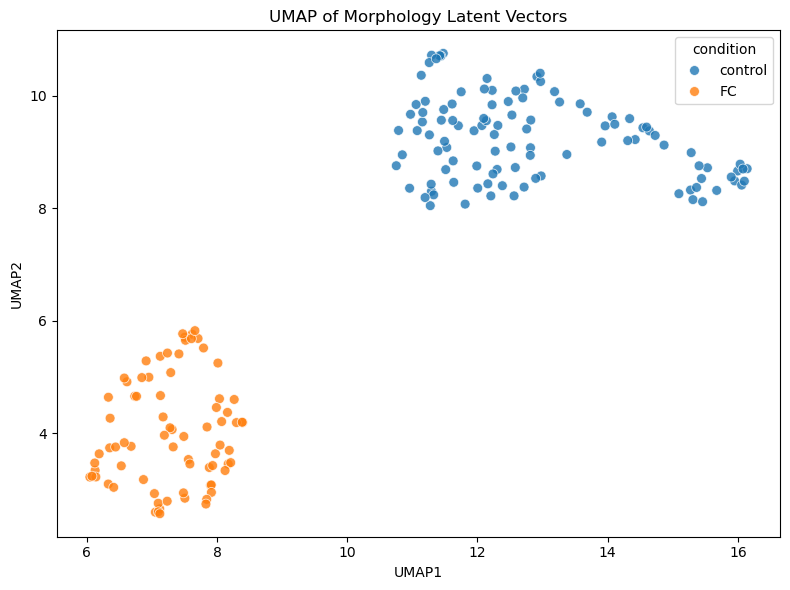

In [10]:
import pandas as pd
import numpy as np

# Load control and FC latent vectors
morph_ctl = pd.read_csv("morphology_latent_vectors_CTL_day3.csv", index_col=0)
morph_fc = pd.read_csv("morphology_latent_vectors_FC_day3.csv", index_col=0)

# Label each group
morph_ctl['condition'] = 'control'
morph_fc['condition'] = 'FC'

# Combine into one dataframe
morph_all = pd.concat([morph_ctl, morph_fc])
features = morph_all.drop(columns='condition')

import umap
import matplotlib.pyplot as plt
import seaborn as sns

# UMAP projection
reducer = umap.UMAP(n_neighbors=15, min_dist=0.1, random_state=42)
embedding = reducer.fit_transform(features)

# Plot
morph_all['UMAP1'] = embedding[:, 0]
morph_all['UMAP2'] = embedding[:, 1]

plt.figure(figsize=(8, 6))
sns.scatterplot(data=morph_all, x='UMAP1', y='UMAP2', hue='condition', s=50, alpha=0.8)
plt.title("UMAP of Morphology Latent Vectors")
plt.tight_layout()
plt.show()


In [2]:
import scanpy as sc
import pandas as pd
import numpy as np
import os

# === Config ===
healthy_path = r"C:\Users\Liyua\Downloads\healthy"
ipf_path = r"C:\Users\Liyua\Downloads\IPF"
aec2_markers = ['SFTPC', 'SFTPB', 'NAPSA', 'LAMP3', 'SFTPA1']
pca_dim = 100

def process_dataset(path, label):
    print(f"Processing {label}...")
    adata = sc.read_10x_mtx(path, var_names='gene_symbols', cache=True)
    
    # Basic filtering
    sc.pp.filter_cells(adata, min_genes=200)
    sc.pp.filter_genes(adata, min_cells=3)
    sc.pp.normalize_total(adata, target_sum=1e4)
    sc.pp.log1p(adata)

    # Score AEC2 cells
    valid_markers = [g for g in aec2_markers if g in adata.var_names]
    sc.tl.score_genes(adata, gene_list=valid_markers, score_name='aec2_score')

    # Filter top AEC2 cells
    aec2 = adata[adata.obs['aec2_score'] > 0.5].copy()
    print(f"Found {aec2.n_obs} AEC2 cells in {label}")

    # PCA
    sc.pp.scale(aec2)
    sc.tl.pca(aec2, n_comps=pca_dim)
    df = pd.DataFrame(aec2.obsm['X_pca'], index=aec2.obs_names)
    df.to_csv(f"gene_latents_{label}.csv")
    return df

# === Run for both datasets
gene_healthy = process_dataset(healthy_path, "healthy")
gene_ipf = process_dataset(ipf_path, "ipf")


ImportError: cannot import name 'cbuffer_sizes' from 'numcodecs.blosc' (C:\Users\Liyua\anaconda3\Lib\site-packages\numcodecs\blosc.cp312-win_amd64.pyd)

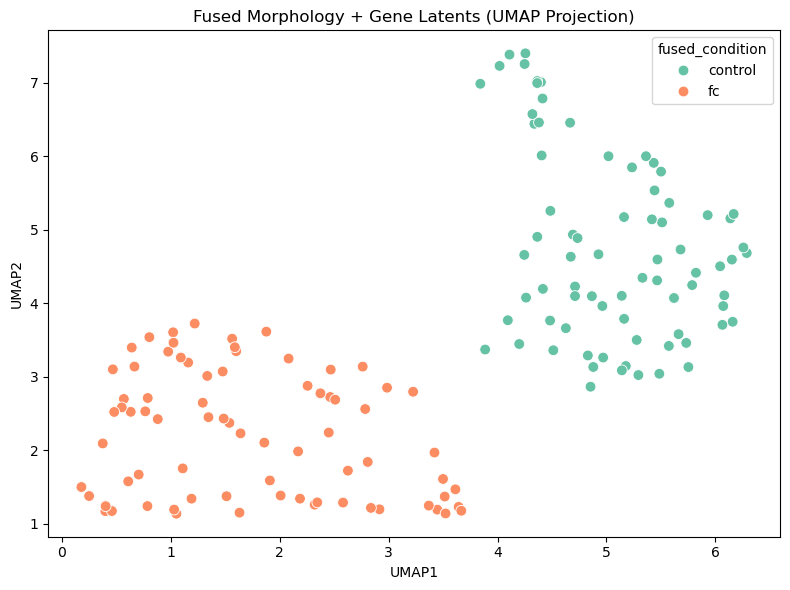

In [6]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
import umap
import matplotlib.pyplot as plt
import seaborn as sns

# Load all 4 datasets
gene_healthy = pd.read_csv("gene_latents_healthy.csv", index_col=0)
gene_ipf = pd.read_csv("gene_latents_ipf.csv", index_col=0)
morph_ctl = pd.read_csv("morphology_latent_vectors_CTL_day3.csv", index_col=0)
morph_fc = pd.read_csv("morphology_latent_vectors_FC_day3.csv", index_col=0)

# Optionally subsample to same number per group
n = min(len(gene_healthy), len(morph_ctl), len(gene_ipf), len(morph_fc))
gene_healthy = gene_healthy.sample(n)
gene_ipf = gene_ipf.sample(n)
morph_ctl = morph_ctl.sample(n)
morph_fc = morph_fc.sample(n)

# Assign condition labels
gene_healthy['condition'] = 'healthy'
gene_ipf['condition'] = 'ipf'
morph_ctl['condition'] = 'control'
morph_fc['condition'] = 'fc'

# Add modality labels
gene_healthy['modality'] = 'gene'
gene_ipf['modality'] = 'gene'
morph_ctl['modality'] = 'morph'
morph_fc['modality'] = 'morph'

# Prepare for fusion
gene_all = pd.concat([gene_healthy, gene_ipf])
morph_all = pd.concat([morph_ctl, morph_fc])

# Align condition labels (e.g., healthy → control, ipf → fc)
map_to_common = {'healthy': 'control', 'ipf': 'fc', 'control': 'control', 'fc': 'fc'}
gene_all['aligned'] = gene_all['condition'].map(map_to_common)
morph_all['aligned'] = morph_all['condition'].map(map_to_common)

# === Fuse by aligned condition (late fusion)
fused = []
for cond in ['control', 'fc']:
    g = gene_all[gene_all['aligned'] == cond].drop(columns=['condition', 'modality', 'aligned']).reset_index(drop=True)
    m = morph_all[morph_all['aligned'] == cond].drop(columns=['condition', 'modality', 'aligned']).reset_index(drop=True)
    fused_block = pd.concat([g, m], axis=1)
    fused_block['fused_condition'] = cond
    fused.append(fused_block)

fused_df = pd.concat(fused).reset_index(drop=True)
features = fused_df.drop(columns='fused_condition')

# === Normalize & UMAP
X_scaled = StandardScaler().fit_transform(features)
embedding = umap.UMAP(n_neighbors=15, min_dist=0.1).fit_transform(X_scaled)
fused_df['UMAP1'], fused_df['UMAP2'] = embedding[:, 0], embedding[:, 1]

# === Plot
plt.figure(figsize=(8, 6))
sns.scatterplot(data=fused_df, x='UMAP1', y='UMAP2', hue='fused_condition', palette='Set2', s=60)
plt.title("Fused Morphology + Gene Latents (UMAP Projection)")
plt.tight_layout()
plt.show()


In [3]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
import xgboost as xgb
import shap
import matplotlib.pyplot as plt
import seaborn as sns

# === Load fused latent vectors ===
gene_ctl = pd.read_csv("gene_latents_healthy.csv", index_col=0).sample(76, random_state=42)
morph_ctl = pd.read_csv("morphology_latent_vectors_CTL_day3.csv", index_col=0).sample(76, random_state=42)
gene_fc = pd.read_csv("gene_latents_ipf.csv", index_col=0).sample(76, random_state=42)
morph_fc = pd.read_csv("morphology_latent_vectors_FC_day3.csv", index_col=0).sample(76, random_state=42)

# === Fuse row-by-row ===
X_control = pd.concat([gene_ctl.reset_index(drop=True), morph_ctl.reset_index(drop=True)], axis=1)
X_fc = pd.concat([gene_fc.reset_index(drop=True), morph_fc.reset_index(drop=True)], axis=1)

# === Combine and label ===
X = pd.concat([X_control, X_fc], axis=0).reset_index(drop=True)
y = pd.Series(['control'] * len(X_control) + ['fc'] * len(X_fc), name="label")

# === Map string labels to integers for XGBoost
label_map = {'control': 0, 'fc': 1}
y_numeric = y.map(label_map)

# === Standardize features
scaler = StandardScaler()
X_scaled = pd.DataFrame(scaler.fit_transform(X), columns=X.columns)

# === Convert to NumPy for SHAP input
X_np = X_scaled.values

# === Train XGBoost model
model = xgb.XGBClassifier(n_estimators=100, use_label_encoder=False, eval_metric='logloss', random_state=42)
model.fit(X_np, y_numeric)

# === SHAP analysis
explainer = shap.Explainer(model, X_np)
shap_values = explainer(X_np)

# === Plot: global bar plot of feature importance
shap.summary_plot(shap_values, features=X_np, feature_names=X_scaled.columns, plot_type="bar")

# === Optional: beeswarm plot for detailed effect by sample
shap.summary_plot(shap_values, features=X_np, feature_names=X_scaled.columns)

# === Optional: top feature inspection
mean_abs_shap = np.abs(shap_values.values).mean(axis=0)
top_features = pd.Series(mean_abs_shap, index=X_scaled.columns).sort_values(ascending=False).head(30)
print("Top 30 most impactful fused features (by SHAP):")
print(top_features)


FileNotFoundError: [Errno 2] No such file or directory: 'gene_latents_healthy.csv'

In [25]:
import pandas as pd

top_shap_features = [110, 80, 99, 12, 33, 94, 3, 117, 112, 108, 6, 54, 53, 20, 57,
                     86, 60, 42, 11, 62, 1, 118, 10, 27, 84, 97, 0, 59, 24, 2]

gene_dim = 128

def map_feature(index, gene_dim):
    if index < gene_dim:
        return 'gene', index
    else:
        return 'morph', index - gene_dim

# Annotate each feature
mapped = []
for idx in top_shap_features:
    src, latent_idx = map_feature(idx, gene_dim)
    mapped.append({'shap_feature_index': idx, 'source': src, 'latent_index': latent_idx})

df_mapped = pd.DataFrame(mapped)
print(df_mapped)


    shap_feature_index source  latent_index
0                  110   gene           110
1                   80   gene            80
2                   99   gene            99
3                   12   gene            12
4                   33   gene            33
5                   94   gene            94
6                    3   gene             3
7                  117   gene           117
8                  112   gene           112
9                  108   gene           108
10                   6   gene             6
11                  54   gene            54
12                  53   gene            53
13                  20   gene            20
14                  57   gene            57
15                  86   gene            86
16                  60   gene            60
17                  42   gene            42
18                  11   gene            11
19                  62   gene            62
20                   1   gene             1
21                 118   gene   

In [30]:
import scanpy as sc

adata = sc.read_10x_mtx("C:/Users/Liyua/Downloads/healthy", var_names="gene_symbols")
sc.pp.filter_cells(adata, min_genes=200)
sc.pp.filter_genes(adata, min_cells=3)
sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)

# Score AEC2 cells
aec2_markers = ['SFTPC', 'SFTPB', 'NAPSA', 'LAMP3', 'SFTPA1']
valid_markers = [g for g in aec2_markers if g in adata.var_names]
sc.tl.score_genes(adata, gene_list=valid_markers, score_name='aec2_score')
aec2 = adata[adata.obs['aec2_score'] > 0.5].copy()

# Scale and PCA
sc.pp.scale(aec2)
sc.tl.pca(aec2, n_comps=128)



C:\Users\Liyua\anaconda3\Lib\functools.py:907: UserWarning: zero-centering a sparse array/matrix densifies it.
  return dispatch(args[0].__class__)(*args, **kw)


In [32]:
import pandas as pd

# varm['PCs'] has shape (n_genes, n_pcs)
pc_idx = 110
pca_weights = pd.Series(aec2.varm['PCs'][:, pc_idx], index=aec2.var_names)

# Sort by absolute contribution
top_genes = pca_weights.abs().sort_values(ascending=False).head(20)

print("Top 20 real genes contributing to gene_latent_110:")
print(top_genes)


Top 20 real genes contributing to gene_latent_110:
GFRA3             0.062947
CTD-2545M3.2      0.061638
RP3-388N13.5      0.061358
RP3-486I3.7       0.053752
CTD-3105H18.14    0.052518
RP11-448G15.1     0.050725
C11orf45          0.049890
RP11-423H2.4      0.049708
KCNA1             0.048024
RP11-479O9.4      0.047311
CNTN5             0.046393
COL23A1           0.043333
LINC00853         0.042198
RP11-195C7.1      0.041970
Z83851.4          0.039415
RDH10-AS1         0.037845
NPAS1             0.037170
AF127936.9        0.035697
PCDH15            0.034681
RP5-991G20.1      0.033893
dtype: float64
